In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, confusion_matrix

pd.set_option('display.float_format', '{:.2f}'.format)

# Step 2: Loading the Data

In [ ]:
data_df = pd.read_csv(
    "/home/nyaugenya/dev/personal/AdvanceDataScience/Credit Risk Prediction/data/raw/train.csv")
data_df.head()

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_257244237466267278,257244,Kenya,237466,267278,Type_1,16477.00,16642.00,2022-08-15,2022-08-22,7,Repeat Loan,2436.00,0.15,2460.00,0
1,ID_249619214444267278,249619,Kenya,214444,267278,Type_1,5599.00,5599.00,2022-07-13,2022-07-20,7,Repeat Loan,2799.50,0.50,2800.00,0
2,ID_251457257838267278,251457,Kenya,257838,267278,Type_1,4679.00,4746.00,2022-09-12,2022-09-19,7,Repeat Loan,7.80,0.00,8.00,0
3,ID_266224270337267278,266224,Kenya,270337,267278,Type_1,6123.00,6123.00,2022-09-29,2022-10-06,7,Repeat Loan,318.80,0.05,319.00,0
4,ID_250369246185267278,250369,Kenya,246185,267278,Type_1,2953.00,2974.00,2022-08-27,2022-09-03,7,Repeat Loan,15.00,0.01,15.00,0


In [14]:
data_df.info()
data_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 68654 entries, 0 to 68653
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           68654 non-null  str    
 1   customer_id                  68654 non-null  int64  
 2   country_id                   68654 non-null  str    
 3   tbl_loan_id                  68654 non-null  int64  
 4   lender_id                    68654 non-null  int64  
 5   loan_type                    68654 non-null  str    
 6   Total_Amount                 68654 non-null  float64
 7   Total_Amount_to_Repay        68654 non-null  float64
 8   disbursement_date            68654 non-null  str    
 9   due_date                     68654 non-null  str    
 10  duration                     68654 non-null  int64  
 11  New_versus_Repeat            68654 non-null  str    
 12  Amount_Funded_By_Lender      68654 non-null  float64
 13  Lender_portion_Funded      

,customer_id,tbl_loan_id,lender_id,Total_Amount,Total_Amount_to_Repay,duration,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
count,68654.00,68654.00,68654.00,68654.00,68654.00,68654.00,68654.00,68654.00,68654.00,68654.00
mean,254392.75,262982.58,266432.65,14592.70,15399.34,8.50,2501.31,0.22,2603.98,0.02
std,26623.53,39328.02,3567.14,133668.37,161157.25,13.43,11486.07,0.13,12916.56,0.13
min,145.00,101323.00,245684.00,5.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,248963.00,233890.50,267278.00,2289.00,2321.00,7.00,239.00,0.12,242.00,0.00
50%,255410.00,260246.50,267278.00,5248.00,5299.00,7.00,909.00,0.30,927.00,0.00
75%,262332.00,286898.75,267278.00,11388.00,11596.00,7.00,2258.40,0.30,2303.00,0.00
max,312737.00,375320.00,267278.00,20000000.00,24152842.00,1096.00,1600000.00,1.17,1821338.00,1.00


In [4]:
data_df.isnull().sum()


ID                             0
customer_id                    0
country_id                     0
tbl_loan_id                    0
lender_id                      0
loan_type                      0
Total_Amount                   0
Total_Amount_to_Repay          0
disbursement_date              0
due_date                       0
duration                       0
New_versus_Repeat              0
Amount_Funded_By_Lender        0
Lender_portion_Funded          0
Lender_portion_to_be_repaid    0
target                         0
dtype: int64

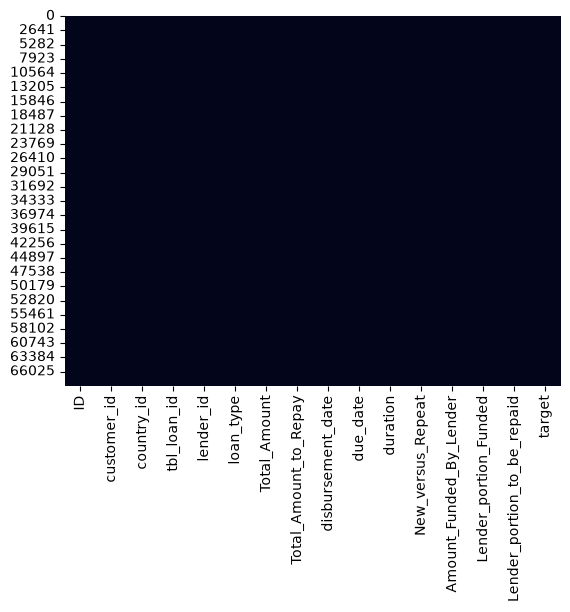

In [5]:
sns.heatmap(data_df.isnull(), cbar=False)
plt.show()

# Step 3: Analyzing Class Distribution

# We separate the dataset into two groups: defaulted loans (target == 1) and repaid loan (target == 0).
It calculates the ratio of defaulted cases to repaid cases to measure how imbalanced the dataset is.
It then prints the outlier fraction along with the number of defaults and valid repaid loans.
This analysis is crucial in fraud detection, as it reveals how rare fraud cases are and whether techniques like resampling or special evaluation metrics are needed 

In [6]:

defaulted = data_df[data_df['target'] == 1]
repaid = data_df[data_df['target'] == 0]
outlierFraction = len(defaulted)/float(len(repaid))
print(outlierFraction)
print('Default Cases: {}'.format(len(data_df[data_df['target'] == 1])))
print('Repaid Loans: {}'.format(len(data_df[data_df['target'] == 0])))
print('Outlier Fraction: {}'.format(
    len(data_df[data_df['target'] == 1])/float(len(data_df[data_df['target'] == 0]))))
print('Total Loans: {}'.format(len(data_df)))
print('Default Rate: {:.2f}%'.format(
    len(data_df[data_df['target'] == 1])/float(len(data_df))*100))
print('Repaid Rate: {:.2f}%'.format(
    len(data_df[data_df['target'] == 0])/float(len(data_df))*100))

0.018665796189684846
Default Cases: 1258
Repaid Loans: 67396
Outlier Fraction: 0.018665796189684846
Total Loans: 68654
Default Rate: 1.83%
Repaid Rate: 98.17%


Ourlier fraction = 0.018665796189684846 ~1.87%
Default Cases: 1258
Repaid Loans: 67396

Step 4: Exploring Transaction Amounts of Defaulted AMounts


In [7]:

# the AMount of defaulted loans

defaulted = data_df[data_df['target'] == 1]
defaulted.Total_Amount.describe()



count       1258.00
mean       88172.03
std       573739.67
min           50.00
25%         3575.00
50%         8093.00
75%        24477.50
max     15000000.00
Name: Total_Amount, dtype: float64

# Details of Repaid Loans

In [8]:
repaid = data_df[data_df['target'] == 0]
repaid.Total_Amount.describe()

count      67396.00
mean       13219.29
std       109353.74
min            5.00
25%         2280.00
50%         5209.50
75%        11257.25
max     20000000.00
Name: Total_Amount, dtype: float64

### from the obeservation the defaulted lons tend to have higher average amounts compaired to repaid loans

Step 5: Plotting Correlation Matrix

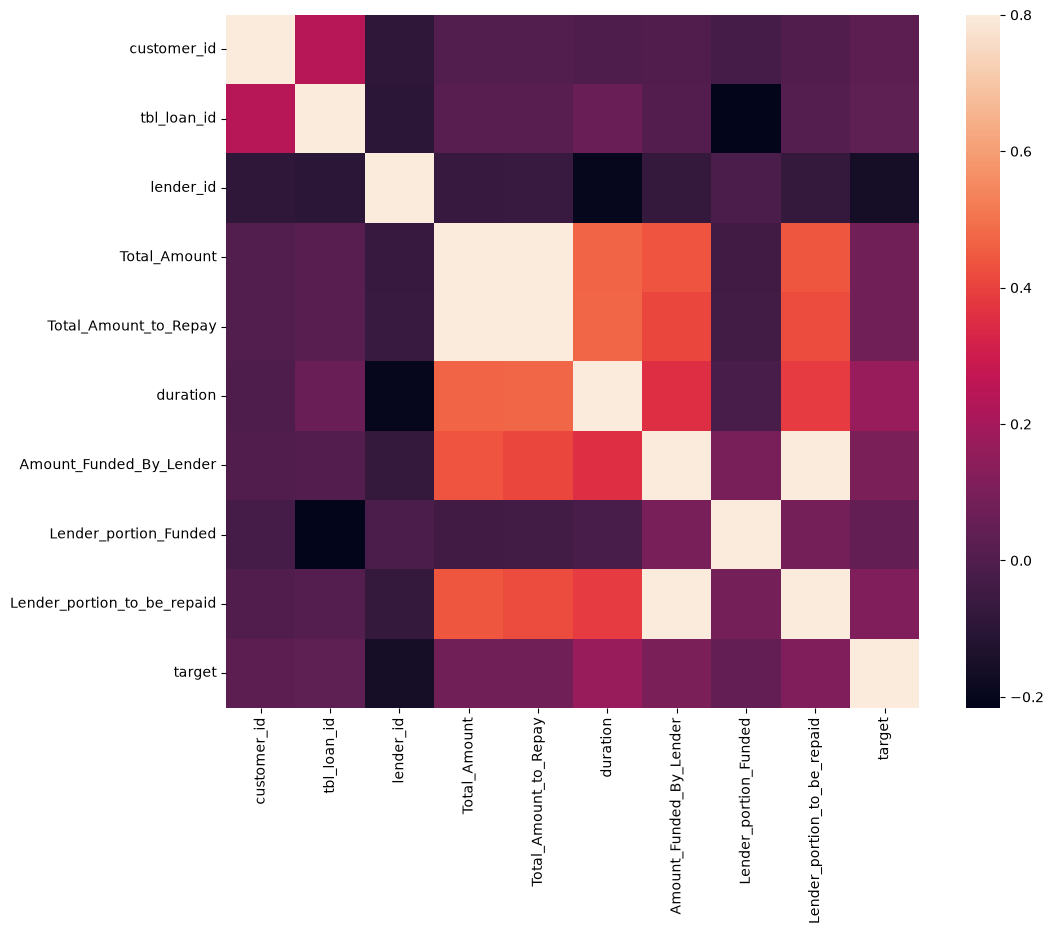

In [9]:
# numerical data
corrmat = data_df.corr(numeric_only=True)
fig = plt.figure(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True)
plt.show()

# Step 6: Preparing Data

In [10]:
numerical_data = data_df.select_dtypes(
    include=['int64', 'float64']).columns
X = data_df[numerical_data].drop(['target'], axis=1)
Y = data_df["target"]
print(X.shape)
print(Y.shape)

xData = X.values
yData = Y.values

xTrain, xTest, yTrain, yTest = train_test_split(
    xData, yData, test_size=0.2, random_state=42)

(68654, 9)
(68654,)


Step 7: Building and Training the Model

In [11]:

rfc = RandomForestClassifier()
rfc.fit(xTrain, yTrain)

yPred = rfc.predict(xTest)

print("Accuracy:", accuracy_score(yTest, yPred))
print("Confusion Matrix:\n", confusion_matrix(yTest, yPred))
print("Classification Report:\n", classification_report(yTest, yPred))

Accuracy: 0.9891486417595222
Confusion Matrix:
 [[13490    12]
 [  137    92]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99     13502
           1       0.88      0.40      0.55       229

    accuracy                           0.99     13731
   macro avg       0.94      0.70      0.77     13731
weighted avg       0.99      0.99      0.99     13731



Step 8: Evaluating the Model

Model Evaluation Metrics:
Accuracy: 0.9891
Precision: 0.8846
Recall: 0.4017
F1-Score: 0.5526
Matthews Correlation Coefficient: 0.5921


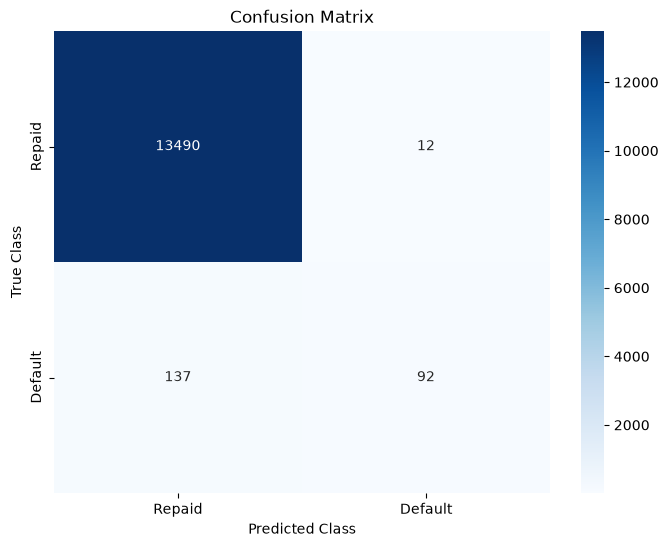

In [12]:

accuracy = accuracy_score(yTest, yPred)
precision = precision_score(yTest, yPred)
recall = recall_score(yTest, yPred)
f1 = f1_score(yTest, yPred)
mcc = matthews_corrcoef(yTest, yPred)

print("Model Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Matthews Correlation Coefficient: {mcc:.4f}")

conf_matrix = confusion_matrix(yTest, yPred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Repaid', 'Default'], yticklabels=['Repaid', 'Default'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()